# 04 - Results (frozen model-v1)
Experiments E1-E5 from blueprint 8.7.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_colwidth', 120)
T = ROOT / 'reports' / 'tables'
F = ROOT / 'reports' / 'figures'

## E1 - model comparison on the cluster-aware test split

,model,key,macro_pr_auc,macro_pr_auc_ci,macro_f1,macro_f1_ci,macro_f2,macro_recall,macro_precision,micro_f1,hamming_loss,label_accuracy,subset_accuracy
0,Majority / prior baseline,prior,0.2271,"[0.193, 0.261]",0.3461,"[0.305, 0.384]",0.5248,1.0000,0.2271,0.3702,0.7729,0.2271,0.0000
1,Logistic regression,logreg,0.8365,"[0.785, 0.866]",0.7373,"[0.693, 0.766]",0.8273,0.9053,0.6296,0.7571,0.1356,0.8644,0.4260
2,Decision tree,tree,0.5842,"[0.482, 0.647]",0.5095,"[0.447, 0.560]",0.6629,0.8377,0.3706,0.5675,0.3145,0.6855,0.1804
3,Random forest,forest,0.8195,"[0.747, 0.856]",0.6797,"[0.632, 0.712]",0.7798,0.8702,0.5656,0.7197,0.1618,0.8382,0.3656
4,K-nearest neighbours,knn,0.6972,"[0.605, 0.746]",0.5865,"[0.520, 0.633]",0.6919,0.7878,0.4691,0.6442,0.2158,0.7842,0.2218
5,MLP neural network,mlp,0.8621,"[0.811, 0.889]",0.7577,"[0.714, 0.787]",0.8260,0.8805,0.6688,0.7764,0.1193,0.8807,0.4618


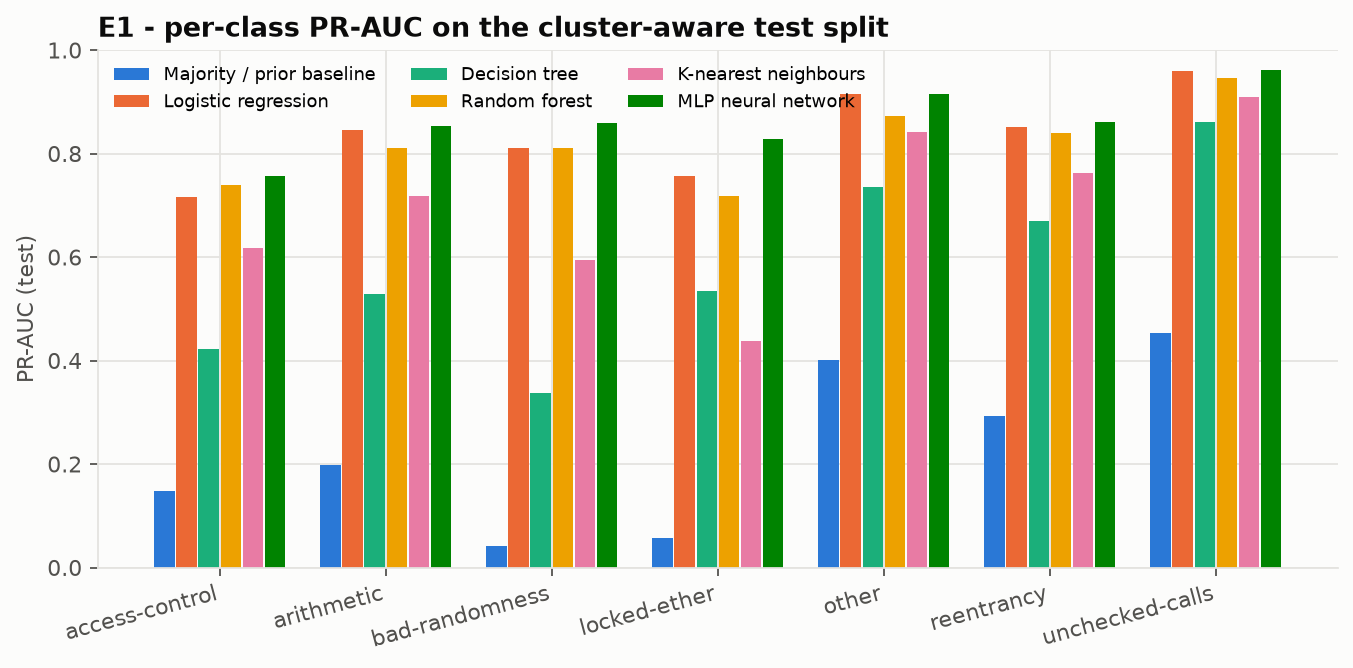

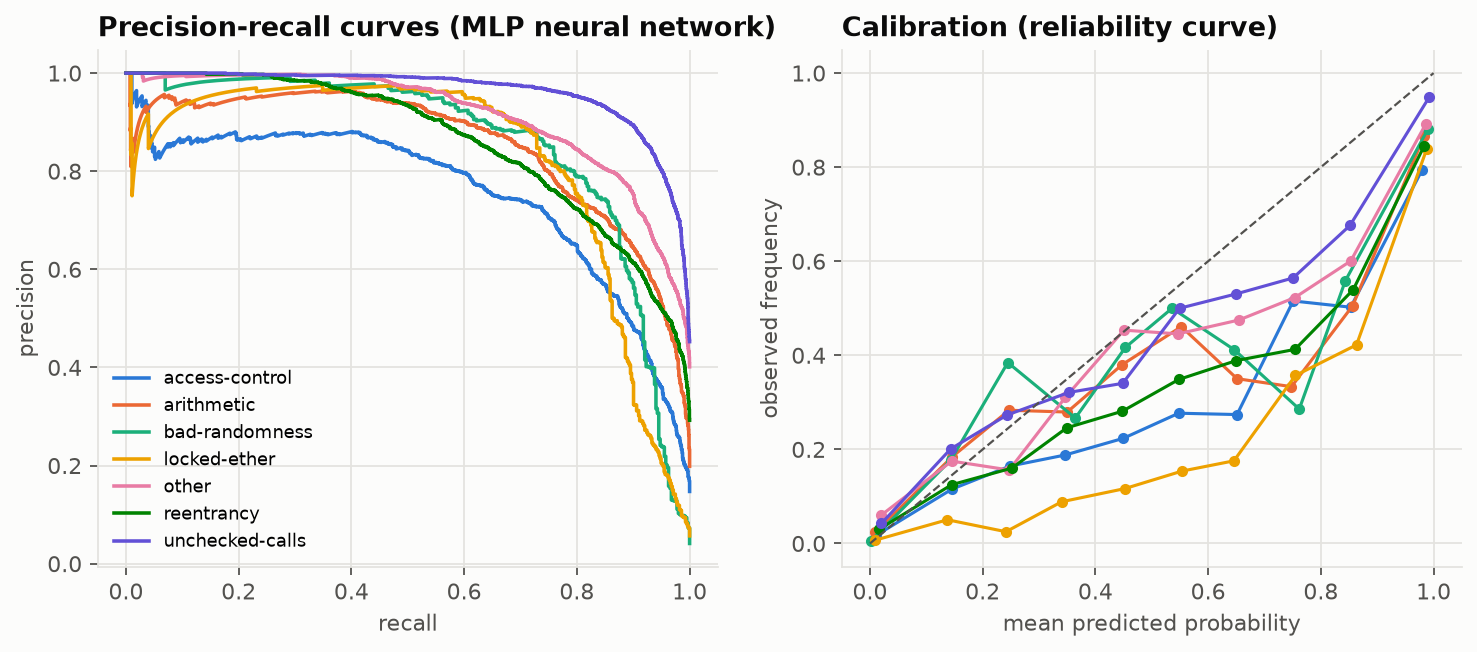

,seed,input,test_macro_pr_auc,test_macro_f1,test_macro_f2
0,42,tfidf,0.8583,0.7459,0.8308
1,43,tfidf,0.8581,0.7424,0.8300
2,44,tfidf,0.8621,0.7577,0.8260
3,mean,NaN,0.8595,0.7487,0.8289
4,std,NaN,0.0019,0.0065,0.0021


In [2]:
display(pd.read_csv(T / 'e1_test_summary.csv'))
display(Image(F / 'e1_per_class_pr_auc.png'))
display(Image(F / 'e1_pr_and_calibration.png'))
pd.read_csv(T / 'e1_mlp_seeds_test.csv')

## E2 - clone leakage (random vs cluster-aware split)

,model,key,cluster_test_macro_pr_auc,random_test_macro_pr_auc,pr_auc_inflation,cluster_test_macro_f1,random_test_macro_f1,f1_inflation
0,Majority / prior baseline,prior,0.2271,0.2206,-0.0065,0.3461,0.3376,-0.0085
1,Logistic regression,logreg,0.8365,0.8707,0.0342,0.7373,0.7773,0.0400
2,Decision tree,tree,0.5842,0.6857,0.1015,0.5095,0.5980,0.0885
3,Random forest,forest,0.8195,0.9094,0.0899,0.6797,0.7845,0.1048
4,K-nearest neighbours,knn,0.6972,0.7656,0.0684,0.5865,0.6430,0.0565
5,MLP neural network,mlp,0.8621,0.9083,0.0462,0.7577,0.8134,0.0557


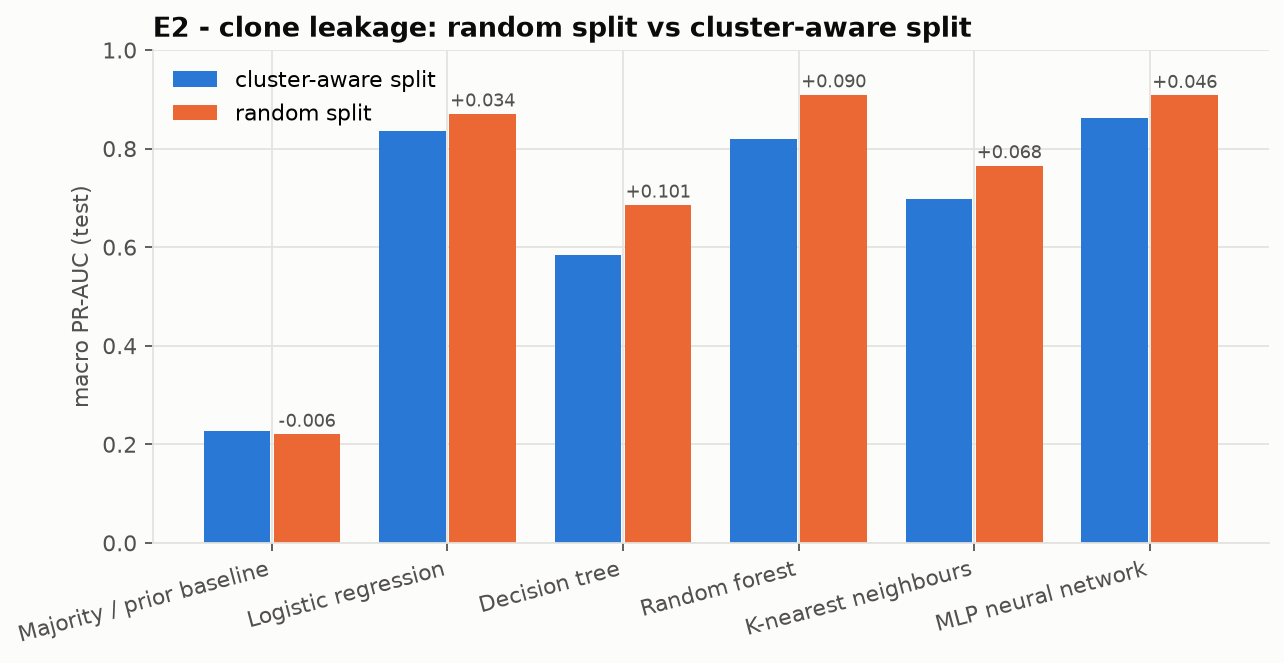

In [3]:
display(pd.read_csv(T / 'e2_leakage.csv'))
display(Image(F / 'e2_leakage.png'))

## E3 - SmartBugs Curated (independent, human-annotated)

In [4]:
display(pd.read_csv(T / 'e3_smartbugs_recall.csv'))
pd.read_csv(T / 'e3_summary.csv')

,smartbugs_category,mapped_class,status,contracts,recall,ci_low,ci_high,mean_probability,any_flag_rate,contracts_no_overlap,recall_no_overlap,ci_low_no_overlap,ci_high_no_overlap
0,unchecked_low_level_calls,unchecked-calls,confirmed,52,0.4808,0.3462,0.6154,0.3489,0.7885,32.0,0.4062,0.2188,0.5938
1,reentrancy,reentrancy,confirmed,31,0.8710,0.7419,0.9677,0.8237,0.9032,13.0,0.7692,0.5385,1.0000
2,bad_randomness,bad-randomness,confirmed,8,0.6250,0.3719,0.8750,0.5364,0.8750,6.0,0.6667,0.3333,1.0000
3,access_control,access-control,partial,18,0.6111,0.3889,0.8333,0.5611,0.6111,18.0,0.6111,0.3889,0.8333
4,arithmetic,-,not evaluated,15,NaN,NaN,NaN,NaN,0.2000,NaN,NaN,NaN,NaN
5,denial_of_service,-,not evaluated,6,NaN,NaN,NaN,NaN,0.5000,NaN,NaN,NaN,NaN
6,time_manipulation,-,not evaluated,5,NaN,NaN,NaN,NaN,0.8000,NaN,NaN,NaN,NaN
7,front_running,-,not evaluated,4,NaN,NaN,NaN,NaN,0.5000,NaN,NaN,NaN,NaN
8,other,-,not evaluated,3,NaN,NaN,NaN,NaN,0.6667,NaN,NaN,NaN,NaN
9,short_addresses,-,not evaluated,1,NaN,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,NaN


,model,key,smartbugs_pooled_recall_confirmed,smartbugs_pooled_recall_confirmed_no_overlap,smartbugs_confirmed_contracts_no_overlap,test_clean_contracts,false_alarm_rate_on_clean_test,macro_fpr_test
0,Majority / prior baseline,prior,1.0000,1.0000,51,2834,1.0000,1.0000
1,Logistic regression,logreg,0.5165,0.4118,51,2834,0.3200,0.1727
2,Decision tree,tree,0.5934,0.4510,51,2834,0.7198,0.4214
3,Random forest,forest,0.4286,0.2157,51,2834,0.3730,0.2059
4,K-nearest neighbours,knn,0.6484,0.5490,51,2834,0.6898,0.2706
5,MLP neural network,mlp,0.6264,0.5294,51,2834,0.2879,0.1477


## E3b - do the highlighted lines hit the annotated lines?

In [5]:
pd.read_csv(T / 'e3b_hit_rate.csv')

,category,contracts,strict@1,strict@1_ci,strict@3,strict@3_ci,relaxed@1,relaxed@1_ci,relaxed@3,relaxed@3_ci,random@1,random@3,random_relaxed@1,random_relaxed@3
0,ALL evaluated (confirmed + partial),109,0.7615,"[0.68, 0.83]",0.8532,"[0.79, 0.92]",0.7982,"[0.72, 0.87]",0.9266,"[0.87, 0.97]",0.0490,0.1415,0.2770,0.5504
1,confirmed classes,91,0.8352,"[0.76, 0.90]",0.9341,"[0.88, 0.98]",0.8681,"[0.80, 0.93]",0.9670,"[0.92, 1.00]",0.0453,0.1317,0.2878,0.5611
2,"confirmed, no overlap with training data",51,0.8431,"[0.75, 0.94]",0.9608,"[0.90, 1.00]",0.8627,"[0.76, 0.94]",0.9804,"[0.94, 1.00]",0.0521,0.1494,0.2703,0.5490
3,"confirmed, flagged by the model",57,0.7895,"[0.68, 0.89]",0.9298,"[0.86, 0.98]",0.8421,"[0.75, 0.93]",0.9825,"[0.95, 1.00]",0.0421,0.1200,0.2750,0.5455
4,access_control (partial),18,0.3889,"[0.17, 0.61]",0.4444,"[0.22, 0.67]",0.4444,"[0.22, 0.67]",0.7222,"[0.50, 0.89]",0.0677,0.1908,0.2229,0.4962
5,bad_randomness (confirmed),8,0.7500,"[0.38, 1.00]",0.8750,"[0.62, 1.00]",0.8750,"[0.62, 1.00]",0.8750,"[0.62, 1.00]",0.0807,0.2022,0.2529,0.5007
6,reentrancy (confirmed),31,0.9032,"[0.77, 1.00]",0.9032,"[0.77, 1.00]",0.9032,"[0.77, 1.00]",0.9677,"[0.90, 1.00]",0.0295,0.0886,0.2538,0.5527
7,unchecked_low_level_calls (confirmed),52,0.8077,"[0.69, 0.92]",0.9615,"[0.90, 1.00]",0.8462,"[0.73, 0.94]",0.9808,"[0.92, 1.00]",0.0492,0.1466,0.3134,0.5754


## E4 - ablations

In [6]:
pd.read_csv(T / 'e4_ablations.csv')

,ablation,setting,test_macro_pr_auc,test_macro_f1,smartbugs_recall_confirmed
0,reference,"comments stripped, identifiers kept, n-grams 1-3",0.8365,0.7373,0.5165
1,comments,comments KEPT on SmartBugs (annotations visible),0.8365,0.7373,0.5604
2,identifiers,user identifiers -> <ID>,0.8589,0.7509,0.4945
3,ngrams,n-grams 1-2,0.8432,0.7360,0.6923
4,ngrams,n-grams 1-1 (bag of tokens),0.8183,0.6985,0.6044


## E5 - latency, error slices and case studies

In [7]:
display(pd.read_csv(T / 'e5_latency.csv'))
display(pd.read_csv(T / 'e5_error_slices.csv'))
pd.DataFrame(json.load(open(T / 'e5_case_studies.json')))

,input,lines,first_predict_ms,warm_predict_ms_median,explain_ms,similar_ms
0,01_clean_token.sol,49.0,61.3428,59.8841,163.4871,244.4712
1,02_reentrancy_bank.sol,24.0,60.2620,60.7618,155.6377,121.0221
2,03_unchecked_send.sol,36.0,65.3900,64.5429,137.5343,100.5624
3,04_weak_randomness_lottery.sol,26.0,60.6866,64.5543,128.6479,104.4979
4,05_tricky_safe_with_keywords.sol,33.0,60.4523,59.3179,135.8176,103.8016
5,06_tricky_renamed_reentrancy.sol,20.0,60.2582,62.5448,122.7988,100.0241
6,smartbugs longest (unchecked_low_level_calls/0x663e4229142a27f00bafb5d087e1e730648314c3.sol),2470.0,102.6131,102.6513,471.8265,NaN
7,synthetic 10x long file,24700.0,401.3623,413.1292,1278.0939,NaN
8,cold start: load all model files,NaN,445.7556,NaN,NaN,NaN


,slice,value,contracts,label_positives,positives_per_contract,micro_recall,micro_precision
0,len_bucket,shortest 25%,2443,1572,0.6435,0.7856,0.5790
1,len_bucket,short-mid,2438,1990,0.8162,0.7975,0.5212
2,len_bucket,mid-long,2438,4967,2.0373,0.9368,0.6656
3,len_bucket,longest 25%,2440,6987,2.8635,0.9551,0.7619
4,solidity,0.4,2057,2487,1.2090,0.8384,0.6134
5,solidity,0.5,1144,1494,1.3059,0.9096,0.6342
6,solidity,0.6,1977,3069,1.5524,0.9238,0.7139
7,solidity,0.7,775,984,1.2697,0.8923,0.5932
8,solidity,0.8,3683,7349,1.9954,0.9359,0.7068
9,solidity,unknown,123,133,1.0813,0.8496,0.5567


,kind,id,class,probability,flagged,top_lines,code_lines,vulnerable_lines,top_line_text,vulnerable_text
0,success,bad_randomness/random_number_generator.sol,bad-randomness,1.000000,True,"[24, 22, 12]",11,"[12, 18, 20, 22]","[return uint256((h / x)) % max + 1;, uint256 h = uint256(blockhash(seed));, uint256 private salt = block.timestamp;]","[uint256 private salt = block.timestamp;, uint256 y = salt * block.number / (salt % 5);, uint256 seed = block.numbe..."
1,success,unchecked_low_level_calls/lotto.sol,unchecked-calls,0.999997,True,"[20, 27, 11]",15,"[20, 27]","[winner.send(winAmount);, msg.sender.send(this.balance);, bool public payedOut = false;]","[winner.send(winAmount);, msg.sender.send(this.balance);]"
2,success,unchecked_low_level_calls/0x663e4229142a27f00bafb5d087e1e730648314c3.sol,unchecked-calls,0.999695,True,"[1152, 425, 749]",1254,"[1152, 1496, 2467]","[msg.sender.send(autoBirthFee);, {, for(; _len >= 32; _len -= 32) {]","[msg.sender.send(autoBirthFee);, bool res = nftAddress.send(this.balance);, cfoAddress.send(balance - subtractFees);]"
3,success,reentrancy/etherstore.sol,reentrancy,0.996954,True,"[27, 16, 14]",17,[27],"[require(msg.sender.call.value(_weiToWithdraw)());, function depositFunds() public payable {, mapping(address => uin...",[require(msg.sender.call.value(_weiToWithdraw)());]
4,success,reentrancy/0x7a8721a9d64c74da899424c1b52acbf58ddc9782.sol,reentrancy,0.996550,True,"[52, 37, 19]",64,[52],"[if(msg.sender.call.value(_am)()), public, require(tx.origin == owner);]",[if(msg.sender.call.value(_am)())]
5,failure,bad_randomness/old_blockhash.sol,bad-randomness,0.000212,False,"[35, 24, 20]",25,[35],"[bytes32 answer = blockhash(guesses[msg.sender].block);, function lockInGuess(bytes32 hash) public payable {, constr...",[bytes32 answer = blockhash(guesses[msg.sender].block);]
6,failure,unchecked_low_level_calls/0x0cbe050f75bc8f8c2d6c0d249fea125fd6e1acc9.sol,unchecked-calls,0.000994,False,[12],6,[12],[a.call();],[a.call();]
7,failure,bad_randomness/lottery.sol,bad-randomness,0.001002,False,"[38, 55, 42]",36,"[38, 42]","[bool won = (block.number % 2) == 0;, if(msg.sender != organizer) { throw; }, bets.push(Bet(msg.value, block.number,...","[bool won = (block.number % 2) == 0;, bets.push(Bet(msg.value, block.number, won));]"
8,failure,reentrancy/modifier_reentrancy.sol,reentrancy,0.002729,False,"[46, 21, 39]",34,[15],"[function call(address token) public{, require(keccak256(abi.encodePacked(""Nu Token"")) == Bank(msg.sender).supportsT...",[function airDrop() hasNoBalance supportsToken public{]
9,failure,reentrancy/reentrancy_bonus.sol,reentrancy,0.565364,True,"[19, 26, 29]",18,[28],"[(bool success, ) = recipient.call.value(amountToWithdraw)("""");, rewardsForA[recipient] += 100;, claimedBonus[recipi...",[withdrawReward(recipient);]
